# RQ3: Laboratory-trained clustering transferred to home recordings

Laboratory XSENS features define two mobility clusters without using fall-history labels. The fitted StandardScaler and cluster models are then applied unchanged to participant-level smartphone features. Final Classification is used only for post hoc comparison.

In [1]:
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency, fisher_exact
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'Clustering':
    PROJECT_ROOT = PROJECT_ROOT.parents[1]

LAB_PATH = PROJECT_ROOT / 'Data/Clustering/Lab/lab_participant_features.csv'
HOME_PATH = PROJECT_ROOT / 'Data/Clustering/Home/home_participant_features.csv'
LABEL_PATH = PROJECT_ROOT / 'Data/lab/4 Test Classification(4 Test Classification).csv'
OUTPUT_PATH = PROJECT_ROOT / 'Data/Clustering/Home/home_lab_transferred_assignments.csv'

LAB_FEATURES = [
    'median_sacrum_walk_duration_s',
    'median_sacrum_walk_cadence_steps_min',
    'median_sacrum_walk_mean_step_time_s',
    'pooled_median_turn_duration_s',
    'pooled_median_turn_step_count',
    'median_sacrum_sit_to_stand_duration_s',
]
HOME_FEATURES = [
    'median_walk_10_step_duration',
    'median_walk_10_step_cadence',
    'median_walk_10_step_mean_step_time',
    'pooled_median_turn_duration_s',
    'pooled_median_turn_step_count',
    'median_sit_to_stand_duration',
]
FEATURE_LABELS = [
    '10-step walking duration (s)',
    '10-step walking cadence (steps/min)',
    '10-step walking mean step time (s)',
    'Pooled turn duration (s)',
    'Pooled turn step count',
    'Sit-to-stand duration (s)',
]
N_CLUSTERS = 2
RANDOM_STATE = 42


In [2]:
labels = pd.read_csv(LABEL_PATH)[['Participant ID', 'Final Classification']].dropna()
labels = labels.drop_duplicates('Participant ID').rename(columns={
    'Participant ID': 'subject_id',
    'Final Classification': 'final_classification',
})
labels['fall_code'] = labels['final_classification'].map({'Non-Faller': 0, 'Faller': 1})

lab = pd.read_csv(LAB_PATH).dropna(subset=LAB_FEATURES).merge(labels, on='subject_id', how='inner')
home = pd.read_csv(HOME_PATH).dropna(subset=HOME_FEATURES).merge(labels, on='subject_id', how='inner')

print(f'Laboratory participants used for training: {len(lab)}')
print(f'Home participants receiving transferred assignments: {len(home)}')

feature_definition_table = pd.DataFrame({
    'Mobility feature': FEATURE_LABELS,
    'Laboratory source': LAB_FEATURES,
    'Home source': HOME_FEATURES,
})
display(feature_definition_table)


Laboratory participants used for training: 16
Home participants receiving transferred assignments: 11


,Mobility feature,Laboratory source,Home source
0,10-step walking duration (s),median_sacrum_walk_duration_s,median_walk_10_step_duration
1,10-step walking cadence (steps/min),median_sacrum_walk_cadence_steps_min,median_walk_10_step_cadence
2,10-step walking mean step time (s),median_sacrum_walk_mean_step_time_s,median_walk_10_step_mean_step_time
3,Pooled turn duration (s),pooled_median_turn_duration_s,pooled_median_turn_duration_s
4,Pooled turn step count,pooled_median_turn_step_count,pooled_median_turn_step_count
5,Sit-to-stand duration (s),median_sacrum_sit_to_stand_duration_s,median_sit_to_stand_duration


In [3]:
# The arrays retain the one-to-one feature order documented above.
lab_feature_matrix = lab[LAB_FEATURES].to_numpy()
home_feature_matrix = home[HOME_FEATURES].to_numpy()
scaler = StandardScaler().fit(lab_feature_matrix)
lab_scaled = scaler.transform(lab_feature_matrix)
home_scaled = scaler.transform(home_feature_matrix)

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=100, random_state=RANDOM_STATE).fit(lab_scaled)
gmm = GaussianMixture(
    n_components=N_CLUSTERS, covariance_type='diag', reg_covar=0.10,
    n_init=100, random_state=RANDOM_STATE,
).fit(lab_scaled)

lab['kmeans_cluster'] = kmeans.predict(lab_scaled)
lab['gmm_cluster'] = gmm.predict(lab_scaled)
home['kmeans_cluster'] = kmeans.predict(home_scaled)
home['gmm_cluster'] = gmm.predict(home_scaled)
home['gmm_membership_probability'] = gmm.predict_proba(home_scaled).max(axis=1)

def map_clusters_from_lab(cluster_values, fall_codes):
    best_mapping, best_agreement = None, -1
    for permutation in permutations(range(N_CLUSTERS)):
        mapping = dict(enumerate(permutation))
        predicted = pd.Series(cluster_values).map(mapping).to_numpy()
        agreement = (predicted == fall_codes).mean()
        if agreement > best_agreement:
            best_mapping, best_agreement = mapping, agreement
    return best_mapping

kmeans_mapping = map_clusters_from_lab(lab['kmeans_cluster'], lab['fall_code'].to_numpy())
gmm_mapping = map_clusters_from_lab(lab['gmm_cluster'], lab['fall_code'].to_numpy())
home['kmeans_lab_profile'] = home['kmeans_cluster'].map(kmeans_mapping)
home['gmm_lab_profile'] = home['gmm_cluster'].map(gmm_mapping)

transfer_assignments = home[[
    'subject_id', 'n_valid_days', 'final_classification', 'kmeans_cluster',
    'kmeans_lab_profile', 'gmm_cluster', 'gmm_lab_profile',
    'gmm_membership_probability',
]].sort_values('subject_id')
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
transfer_assignments.to_csv(OUTPUT_PATH, index=False)
display(transfer_assignments)


,subject_id,n_valid_days,final_classification,kmeans_cluster,kmeans_lab_profile,gmm_cluster,gmm_lab_profile,gmm_membership_probability
0,SRS02,14,Non-Faller,0,0,1,1,1.000000
1,SRS03,14,Faller,1,1,1,1,1.000000
2,SRS04,14,Non-Faller,0,0,1,1,0.995326
3,SRS05,14,Non-Faller,0,0,1,1,1.000000
4,SRS08,14,Non-Faller,0,0,0,0,1.000000
5,SRS09,14,Non-Faller,0,0,0,0,1.000000
6,SRS10,14,Non-Faller,0,0,0,0,1.000000
7,SRS11,14,Non-Faller,0,0,0,0,1.000000
8,SRS15,14,Faller,0,0,1,1,0.565988
9,SRS16,14,Faller,1,1,1,1,1.000000


In [4]:
home_labeled = home.dropna(subset=['fall_code']).copy()

def transfer_statistics(profile_column):
    profile = home_labeled[profile_column].astype(int).to_numpy()
    fall_codes = home_labeled['fall_code'].astype(int).to_numpy()
    contingency = pd.crosstab(profile, fall_codes).reindex(
        index=range(N_CLUSTERS), columns=range(N_CLUSTERS), fill_value=0
    )
    _, fisher_p = fisher_exact(contingency.to_numpy())
    chi_square, _, _, _ = chi2_contingency(contingency.to_numpy(), correction=False)
    return {
        'contingency': contingency,
        'fisher_p': fisher_p,
        'phi': (chi_square / len(home_labeled)) ** 0.5,
        'agreement': (profile == fall_codes).mean() * 100,
    }

kmeans_result = transfer_statistics('kmeans_lab_profile')
gmm_result = transfer_statistics('gmm_lab_profile')

display(pd.DataFrame([
    {
        'Model': 'Laboratory-trained K-means',
        'Participants': len(home_labeled),
        "Fisher's exact test": f"p = {kmeans_result['fisher_p']:.3f}",
        'Phi correlation coefficient': f"{kmeans_result['phi']:.3f}",
        'Agreement': f"{kmeans_result['agreement']:.1f}%",
    },
    {
        'Model': 'Laboratory-trained GMM',
        'Participants': len(home_labeled),
        "Fisher's exact test": f"p = {gmm_result['fisher_p']:.3f}",
        'Phi correlation coefficient': f"{gmm_result['phi']:.3f}",
        'Agreement': f"{gmm_result['agreement']:.1f}%",
    },
]))


,Model,Participants,Fisher's exact test,Phi correlation coefficient,Agreement
0,Laboratory-trained K-means,11,p = 0.109,0.624,81.8%
1,Laboratory-trained GMM,11,p = 0.545,0.311,63.6%


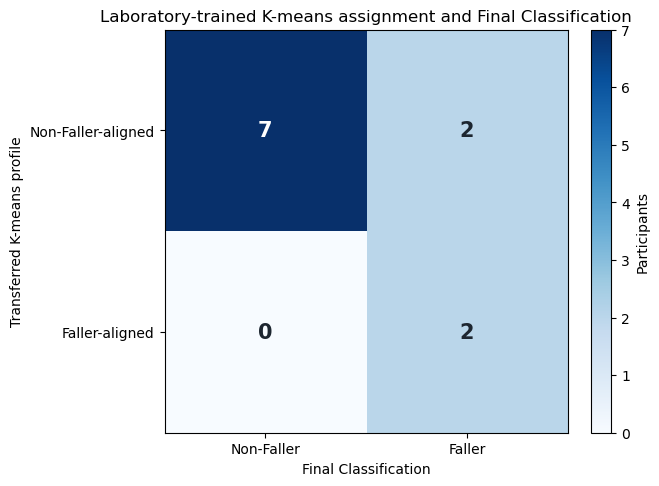

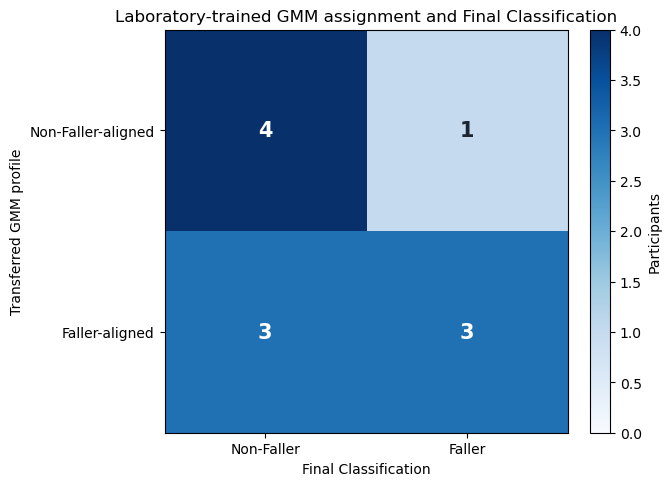

In [5]:
def plot_heatmap(contingency, title, ylabel):
    fig, ax = plt.subplots(figsize=(6.5, 4.75), constrained_layout=True)
    matrix = contingency.to_numpy()
    image = ax.imshow(matrix, cmap='Blues', vmin=0)
    ax.set_xticks(range(N_CLUSTERS), ['Non-Faller', 'Faller'])
    ax.set_yticks(range(N_CLUSTERS), ['Non-Faller-aligned', 'Faller-aligned'])
    ax.set_xlabel('Final Classification')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    for row in range(N_CLUSTERS):
        for column in range(N_CLUSTERS):
            value = matrix[row, column]
            ax.text(column, row, str(value), ha='center', va='center',
                    fontsize=15, fontweight='semibold',
                    color='white' if value >= matrix.max() / 2 else '#1d2630')
    fig.colorbar(image, ax=ax, label='Participants')
    plt.show()

plot_heatmap(
    kmeans_result['contingency'],
    'Laboratory-trained K-means assignment and Final Classification',
    'Transferred K-means profile',
)
plot_heatmap(
    gmm_result['contingency'],
    'Laboratory-trained GMM assignment and Final Classification',
    'Transferred GMM profile',
)


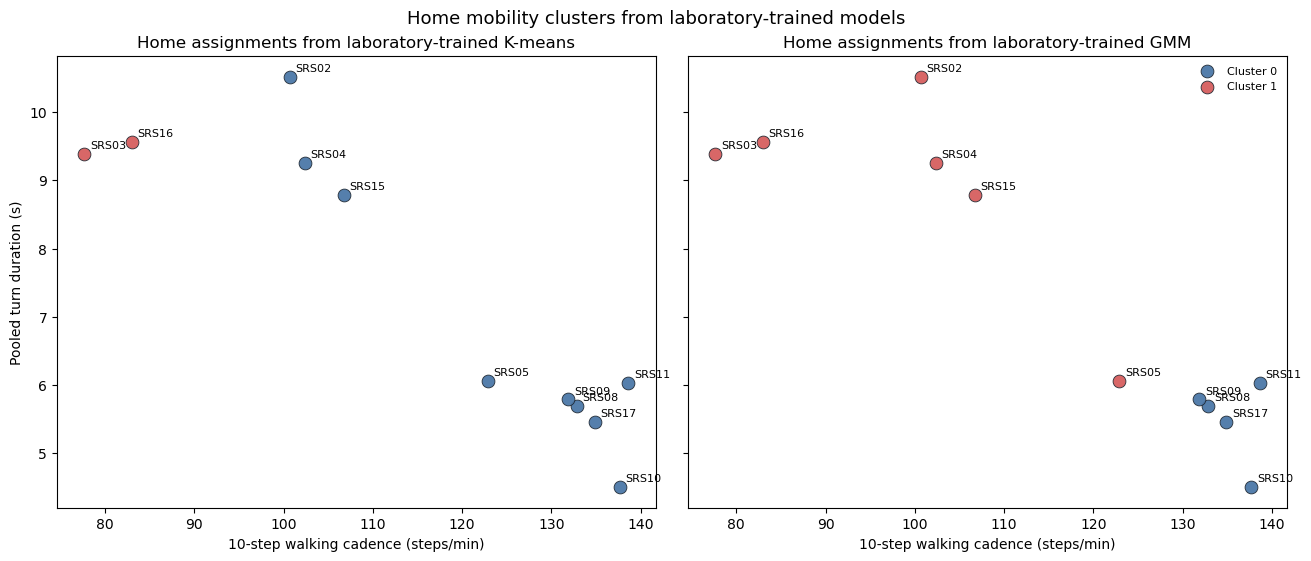

In [6]:
home_x = home['median_walk_10_step_cadence'].to_numpy()
home_y = home['pooled_median_turn_duration_s'].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True, constrained_layout=True)
models = [('K-means', 'kmeans_cluster'), ('GMM', 'gmm_cluster')]
colors = {0: '#4c78a8', 1: '#d65f5f'}
for ax, (model_name, cluster_column) in zip(axes, models):
    for cluster in range(N_CLUSTERS):
        home_mask = home[cluster_column].to_numpy() == cluster
        ax.scatter(home_x[home_mask], home_y[home_mask], s=85, color=colors[cluster],
                   edgecolor='#1d2630', linewidth=.6, label=f'Cluster {cluster}', alpha=.95)
    for x, y, participant in zip(home_x, home_y, home['subject_id']):
        ax.annotate(participant, (x, y), xytext=(4, 4), textcoords='offset points', fontsize=8)
    ax.set_xlabel('10-step walking cadence (steps/min)')
    ax.set_title(f'Home assignments from laboratory-trained {model_name}')
axes[0].set_ylabel('Pooled turn duration (s)')
axes[1].legend(frameon=False, fontsize=8, loc='best')
fig.suptitle('Home mobility clusters from laboratory-trained models', fontsize=13)
plt.show()


## Laboratory-fitted PCA view of transferred home clusters

PCA is fitted on the standardized laboratory feature matrix and then applied unchanged to the home feature matrix. Only home participants are displayed.

In [7]:
from sklearn.decomposition import PCA

transfer_pca = PCA().fit(lab_scaled)
explained_variance = transfer_pca.explained_variance_ratio_ * 100
cumulative_variance = explained_variance.cumsum()

transfer_pca_variance_table = pd.DataFrame({
    'Principal component': [f'PC{i}' for i in range(1, len(explained_variance) + 1)],
    'Explained variance (%)': explained_variance,
    'Cumulative variance (%)': cumulative_variance,
}).round(2)

transfer_pca_retention_summary = pd.DataFrame([
    {
        'Variance retained': f'{threshold}%',
        'Components required': int((cumulative_variance < threshold).sum() + 1),
    }
    for threshold in (80, 90, 95)
])

display(transfer_pca_variance_table)
display(transfer_pca_retention_summary)


,Principal component,Explained variance (%),Cumulative variance (%)
0,PC1,65.57,65.57
1,PC2,19.57,85.15
2,PC3,14.14,99.28
3,PC4,0.50,99.78
4,PC5,0.22,100.00
5,PC6,0.00,100.00


,Variance retained,Components required
0,80%,2
1,90%,3
2,95%,3


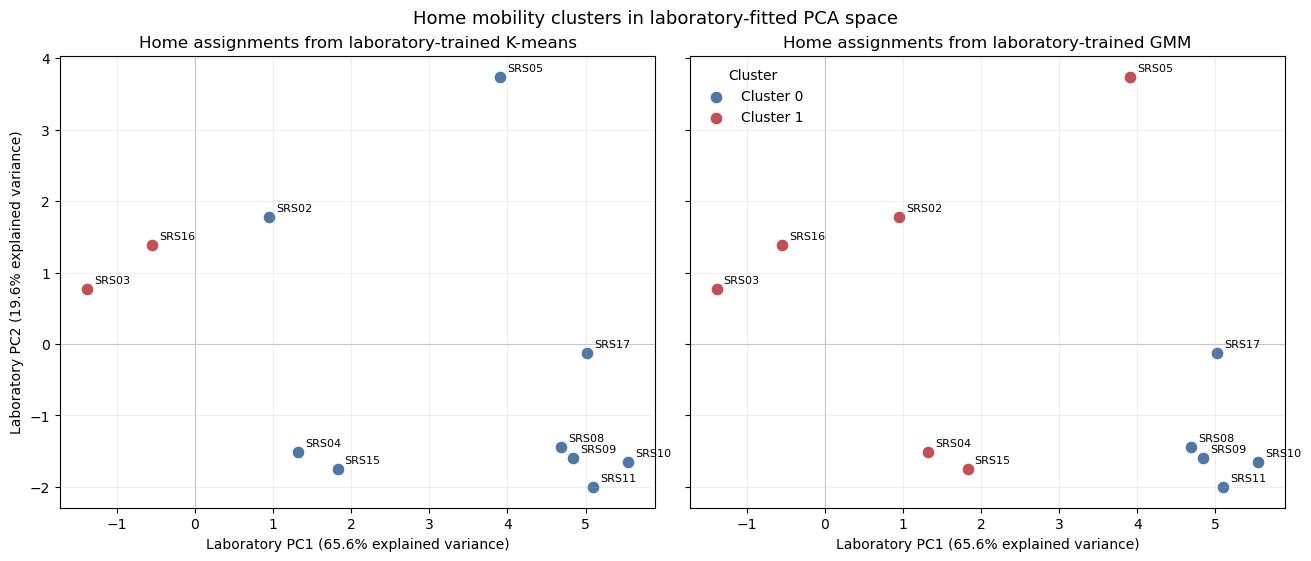

In [8]:
home_pca_two_components = transfer_pca.transform(home_scaled)[:, :2]
pc1_variance, pc2_variance = explained_variance[:2]
cluster_colors = {0: '#4C78A8', 1: '#C44E52'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True, constrained_layout=True)
models = [('K-means', 'kmeans_cluster'), ('GMM', 'gmm_cluster')]
for ax, (model_name, cluster_column) in zip(axes, models):
    for cluster, color in cluster_colors.items():
        mask = home[cluster_column].to_numpy() == cluster
        ax.scatter(
            home_pca_two_components[mask, 0], home_pca_two_components[mask, 1],
            s=85, color=color, edgecolor='white', linewidth=.8,
            label=f'Cluster {cluster}',
        )
    for point, participant in zip(home_pca_two_components, home['subject_id']):
        ax.annotate(participant, point, xytext=(5, 4), textcoords='offset points', fontsize=8)
    ax.axhline(0, color='#c7c7c7', linewidth=.8)
    ax.axvline(0, color='#c7c7c7', linewidth=.8)
    ax.set_xlabel(f'Laboratory PC1 ({pc1_variance:.1f}% explained variance)')
    ax.set_title(f'Home assignments from laboratory-trained {model_name}')
    ax.grid(alpha=.20)
axes[0].set_ylabel(f'Laboratory PC2 ({pc2_variance:.1f}% explained variance)')
axes[1].legend(title='Cluster', frameon=False)
fig.suptitle('Home mobility clusters in laboratory-fitted PCA space', fontsize=13)
plt.show()
